In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
PROCESSED_DATA_DIR = PROJECT_ROOT / "data" / "processed"

train_df = pd.read_csv(RAW_DATA_DIR / "banking77_train.csv")
test_df = pd.read_csv(RAW_DATA_DIR / "banking77_test.csv")

print("Training shape:", train_df.shape)
print("Test shape:", test_df.shape)

Training shape: (10003, 2)
Test shape: (3080, 2)


### Create text-length features

In [3]:
eda_df = train_df.copy()

eda_df["character_count"] = eda_df["text"].str.len()

eda_df["word_count"] = eda_df["text"].apply(
    lambda text: len(str(text).split())
)

display(eda_df[["text", "category", "character_count", "word_count"]].head())

print("\nCharacter count statistics:")
display(eda_df["character_count"].describe())

print("\nWord count statistics:")
display(eda_df["word_count"].describe())

,text,category,character_count,word_count
0,I am still waiting on my card?,card_arrival,30,7
1,What can I do if my card still hasn't arrived ...,card_arrival,60,13
2,I have been waiting over a week. Is the card s...,card_arrival,58,12
3,Can I track my card while it is in the process...,card_arrival,59,13
4,"How do I know if I will get my card, or if it ...",card_arrival,54,15



Character count statistics:


count    10003.000000
mean        59.473758
std         40.867901
min         13.000000
25%         36.000000
50%         47.000000
75%         64.000000
max        433.000000
Name: character_count, dtype: float64


Word count statistics:


count    10003.000000
mean        11.949415
std          7.891577
min          2.000000
25%          7.000000
50%         10.000000
75%         13.000000
max         79.000000
Name: word_count, dtype: float64

### Observations
The dataset contains customer-service messages related to banking operations.

The dataset has 77 unique intent categories.

The training data contains 10,003 records, and the official test data contains 3,080 records.

Each record contains a customer message (text) and its corresponding intent (category).

The training data was used for EDA. The original raw CSV files were preserved.

### Plot intent distribution

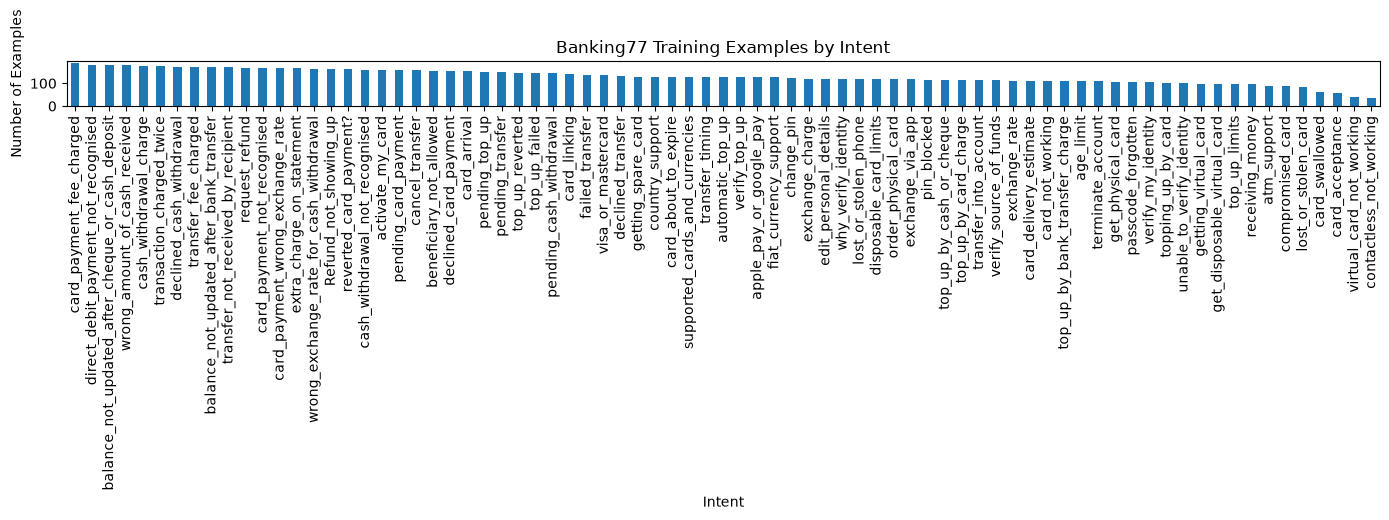

Largest intent count: 187
Smallest intent count: 35
Largest-to-smallest count ratio: 5.34


In [4]:
intent_counts = train_df["category"].value_counts()

plt.figure(figsize=(14, 5))
intent_counts.plot(kind="bar")
plt.title("Banking77 Training Examples by Intent")
plt.xlabel("Intent")
plt.ylabel("Number of Examples")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

print("Largest intent count:", intent_counts.max())
print("Smallest intent count:", intent_counts.min())
print("Largest-to-smallest count ratio:", round(intent_counts.max() / intent_counts.min(), 2))

### Plot the distribution of text lengths

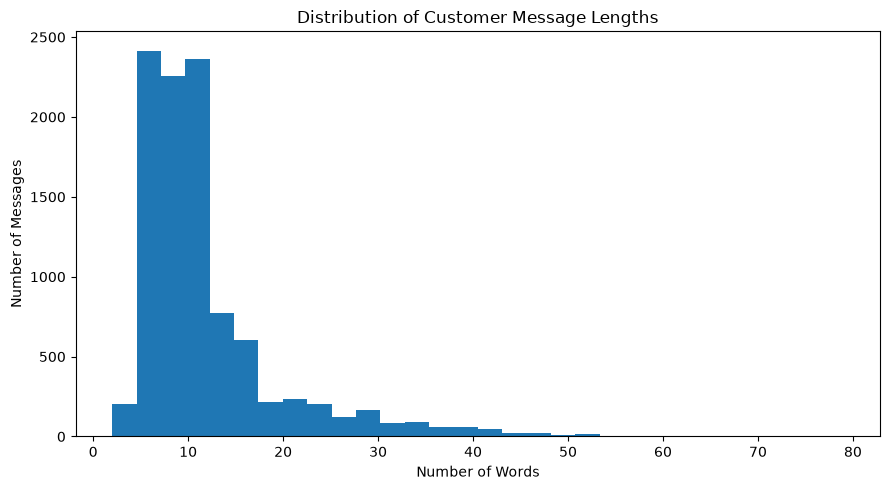

In [5]:
plt.figure(figsize=(9, 5))
plt.hist(eda_df["word_count"], bins=30)
plt.title("Distribution of Customer Message Lengths")
plt.xlabel("Number of Words")
plt.ylabel("Number of Messages")
plt.tight_layout()
plt.show()

### Inspect the shortest and longest messages

In [ ]:
print("Five shortest messages:")
display(eda_df.sort_values("word_count")[
        ["text", "category", "word_count"]].head())

print("\nFive longest messages:")
display(eda_df.sort_values("word_count", ascending=False)[
        ["text", "category", "word_count"]].head())

Five shortest messages:


,text,category,word_count
9979,Supported countries,country_support,2
4889,Lost password,passcode_forgotten,2
4847,passcode retrieval,passcode_forgotten,2
5561,Transfer declined.,declined_transfer,2
5176,pending transaction?,pending_card_payment,2



Five longest messages:


,text,category,word_count
3917,Hearing back from us regarding your important ...,unable_to_verify_identity,79
7310,Hi! I'm a university student studying abroad a...,transfer_fee_charged,78
3934,Hearing about your verification results from u...,unable_to_verify_identity,75
3905,You will hear back from us about your verifica...,unable_to_verify_identity,70
3910,It can take between 10 minutes to an hour befo...,unable_to_verify_identity,70


### Find common words

In [7]:
all_words = " ".join(train_df["text"].astype(str)).lower().split()

word_counts = Counter(all_words)

common_words_df = pd.DataFrame(word_counts.most_common(30),
    columns=["word", "frequency"])

display(common_words_df)

,word,frequency
0,i,8309
1,my,5684
2,to,4011
3,a,3565
4,the,3497
5,is,2339
6,can,1839
7,do,1730
8,card,1636
9,it,1557


### Observations:
The most frequent words in the raw customer messages included i, my, to, a, the, is, can, do, card, and account.

Many frequent words are common conversational words rather than banking-specific terms. Words such as card, money, transfer, and payment provide useful information about the subject of customer queries.

The word not also appeared frequently. This is important because negation can change the meaning of a message. For example, “I made a withdrawal” and “I did not make a withdrawal” describe very different situations.

Common-word frequency alone does not explain customer intent. Both banking-specific terms and the surrounding context must be considered

### Find frequent unigrams and bigrams

In [ ]:
vectorizer = CountVectorizer(
    lowercase=True,
    stop_words="english",
    ngram_range=(1, 2),
    max_features=50
)

word_matrix = vectorizer.fit_transform(train_df["text"])

word_frequencies = word_matrix.sum(axis=0).A1
terms = vectorizer.get_feature_names_out()

top_terms_df = pd.DataFrame({
    "term": terms,
    "frequency": word_frequencies}).sort_values("frequency", ascending=False)

display(top_terms_df.head(30))

,term,frequency
3,card,2682
0,account,1352
28,money,1133
41,transfer,1084
32,payment,751
29,need,698
5,cash,691
15,exchange,549
8,charged,529
2,atm,482


### Observations:
Using CountVectorizer with English stop-word removal and unigram/bigram features, frequently occurring terms included:

card, account, money, transfer, payment, cash, exchange rate, transaction, fees, declined

These terms indicate that customer messages frequently concern cards, accounts, money transfers, payments, cash withdrawals, fees, and exchange rates.

Bigrams such as exchange rate can capture useful phrases that individual words may not represent as clearly.

The results also included fragments such as didn and don. This occurs because the default tokenization used by CountVectorizer can split contractions in unexpected ways.

Word and phrase features provide useful information for text classification, but tokenization and contraction handling should be examined during preprocessing.


### Inspect messages for selected intents


In [15]:
selected_intents = [
    "cash_withdrawal_charge",
    "cash_withdrawal_not_recognised",
    "declined_cash_withdrawal",
    "pending_cash_withdrawal",
    "wrong_exchange_rate_for_cash_withdrawal"
]

for intent in selected_intents:
    count = (train_df["category"] == intent).sum()
    print(f"{intent}: {count} examples")

cash_withdrawal_charge: 177 examples
cash_withdrawal_not_recognised: 160 examples
declined_cash_withdrawal: 173 examples
pending_cash_withdrawal: 143 examples
wrong_exchange_rate_for_cash_withdrawal: 163 examples


In [17]:
for intent in selected_intents:
    examples = train_df.loc[
        train_df["category"] == intent, "text"
    ].head(5)

    print(f"\nIntent: {intent}")

    for example in examples:
        print("-", example)


Intent: cash_withdrawal_charge
- Why is there a charge when I took out money?
- Why have I been charged a fee for cash withdrawal?
- I made a cash withdrawl and there is a charge.  What is this?
- I am inquiring about why there was an extra fee charged when I used an ATM.
- Why am I being charged extra when I withdrew money?

Intent: cash_withdrawal_not_recognised
- I looked on the app and it says I withdrew cash.  I didn't!
- I didn't withdraw the amount of cash that is showing up in the app.
- I saw on the app that a cash withdrawal was completed on my account; however, I did not complete it.
- I got a notice from my app that I withdrew cash but I don't remember doing so. How do I fix this?
- Someone has a copy of my card !! I definitely still have it here but someone just made a 500£ cash withdrawal, HELP!

Intent: declined_cash_withdrawal
- I tried to withdraw cash and got declined, why is that?
- Why was I declined when I tried to get my money?
- I could not access my money at th

### Observations: 
Exact label names must be verified against the dataset. Similar banking terms can also describe different customer intents, so the classifier must learn the context rather than rely on individual keywords.
punctuation, and informal expressions.

Examples included:

“I didn't!”

“Why have I been charged a fee for cash withdrawal?”

“I made a cash withdrawl and there is a charge.”

These patterns are common in real-world customer-support text. A preprocessing pipeline should handle inconsistent formatting carefully without removing information required to understand the customer's intent.

Negation words such as not and didn't are especially important for banking complaints, including reports of unauthorized transactions.

### Save EDA results

In [10]:
PROCESSED_DATA_DIR.mkdir(parents=True, exist_ok=True)

eda_df.to_csv(
    PROCESSED_DATA_DIR / "banking77_train_eda.csv",
    index=False
)

top_terms_df.to_csv(
    PROCESSED_DATA_DIR / "phase2_top_terms.csv",
    index=False
)

print("EDA results saved.")

EDA results saved.
